In [1]:
import os
import sys

PROJECT_PATH = r"C:\docx\Predictive_Maintenance"

os.chdir(PROJECT_PATH)

if PROJECT_PATH not in sys.path:
    sys.path.insert(0, PROJECT_PATH)

print("Working directory:", os.getcwd())

Working directory: C:\docx\Predictive_Maintenance


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap

from src.data_preparation import (
    load_data,
    prepare_data,
    FEATURES
)

df = load_data()

X_train, X_test, y_train, y_test = prepare_data(df)

rf_model = joblib.load(
    os.path.join(PROJECT_PATH, "best_random_forest.joblib")
)

anomaly_model = joblib.load(
    os.path.join(PROJECT_PATH, "isolation_forest.joblib")
)

print("Data and models loaded successfully.")
print("Training records:", len(X_train))
print("Test records:", len(X_test))
print("Features:", FEATURES)

Data and models loaded successfully.
Training records: 8000
Test records: 2000
Features: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


In [3]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [4]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score

rf_importance = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

rf_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": rf_importance.importances_mean,
    "Std": rf_importance.importances_std
}).sort_values("Importance", ascending=False)

display(rf_importance_df)

,Feature,Importance,Std
4,Torque [Nm],0.544739,0.012915
3,Rotational speed [rpm],0.492688,0.006607
1,Air temperature [K],0.437009,0.061135
5,Tool wear [min],0.274475,0.011084
2,Process temperature [K],0.190724,0.017503
0,Type,0.043645,0.012400


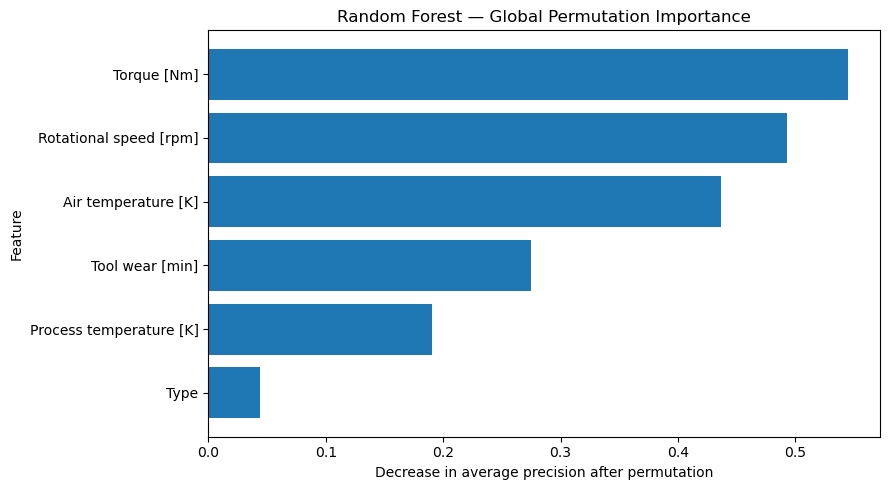

In [5]:
plot_data = rf_importance_df.sort_values("Importance")

plt.figure(figsize=(9, 5))
plt.barh(plot_data["Feature"], plot_data["Importance"])
plt.xlabel("Decrease in average precision after permutation")
plt.ylabel("Feature")
plt.title("Random Forest — Global Permutation Importance")
plt.tight_layout()
plt.show()

In [7]:
import shap
import numpy as np
import pandas as pd

# Select a small background dataset and records to explain
X_background = X_train.sample(
    n=min(50, len(X_train)),
    random_state=42
).copy()

X_explain = X_test.sample(
    n=min(20, len(X_test)),
    random_state=42
).copy()

# SHAP will pass numeric arrays to this function.
# Convert each array back into the original feature DataFrame.
def failure_probability_function(data):
    if isinstance(data, pd.DataFrame):
        input_df = data[FEATURES].copy()
    else:
        input_df = pd.DataFrame(data, columns=FEATURES)

    # The Random Forest pipeline handles Type preprocessing itself.
    return rf_model.predict_proba(input_df)[:, 1]


# Create numeric encodings only for SHAP's masker.
# Keep a mapping to recover the original category values.
type_categories = sorted(X_train["Type"].dropna().unique())
type_to_code = {
    category: index
    for index, category in enumerate(type_categories)
}

def encode_for_shap(data):
    encoded = data[FEATURES].copy()
    encoded["Type"] = encoded["Type"].map(type_to_code)
    return encoded.astype(float)


def decode_from_shap(data):
    if isinstance(data, pd.DataFrame):
        decoded = data[FEATURES].copy()
    else:
        decoded = pd.DataFrame(data, columns=FEATURES)

    codes = np.rint(decoded["Type"].to_numpy()).astype(int)

    # Guard against invalid category codes
    codes = np.clip(codes, 0, len(type_categories) - 1)

    decoded["Type"] = [
        type_categories[code] for code in codes
    ]

    for column in FEATURES:
        if column != "Type":
            decoded[column] = pd.to_numeric(
                decoded[column], errors="raise"
            )

    return decoded[FEATURES]


def shap_model_function(encoded_data):
    original_data = decode_from_shap(encoded_data)
    return failure_probability_function(original_data)


background_encoded = encode_for_shap(X_background)
explain_encoded = encode_for_shap(X_explain)

explainer = shap.PermutationExplainer(
    shap_model_function,
    background_encoded
)

shap_values = explainer(
    explain_encoded,
    max_evals=2 * len(FEATURES) * 10 + 1
)

print("SHAP explanation completed.")
print("SHAP values shape:", shap_values.values.shape)

SHAP explanation completed.
SHAP values shape: (20, 6)


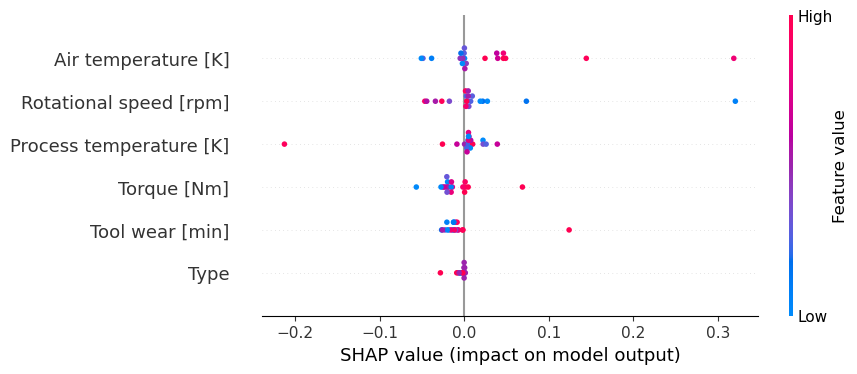

In [8]:
shap.plots.beeswarm(shap_values)

SHAP values shape: (20, 6)
Explained data shape: (20, 6)


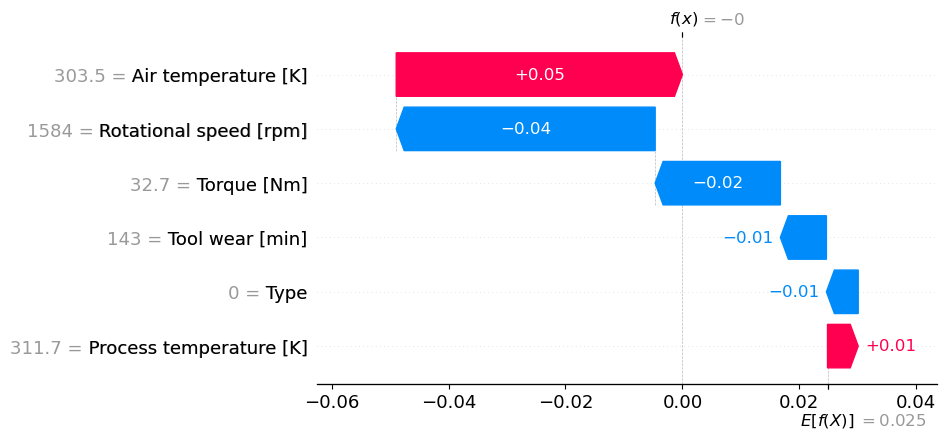

In [20]:
print("SHAP values shape:", shap_values.values.shape)
print("Explained data shape:", explain_encoded.shape)

failure_shap = shap.Explanation(
    values=shap_values.values,
    base_values=shap_values.base_values,
    data=explain_encoded.to_numpy(),
     feature_names=X_explain.columns.tolist()
)
shap.plots.waterfall(failure_shap[0])

Machine index: 4632
Predicted failure probability: 0.7422


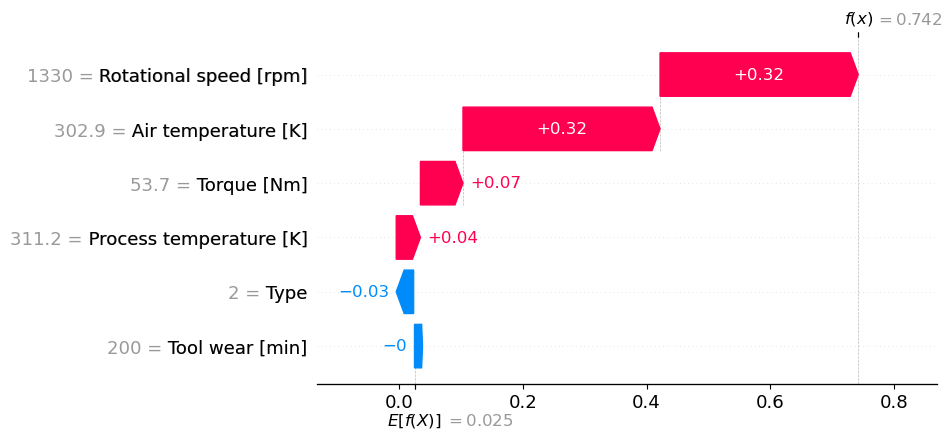

In [19]:
# Select the machine with the highest predicted failure probability
risk_probabilities = rf_model.predict_proba(X_explain)[:, 1]
local_position = np.argmax(risk_probabilities)

print("Machine index:", X_explain.index[local_position])
print("Predicted failure probability:",
      round(risk_probabilities[local_position], 4))

# Explain this individual prediction
shap.plots.waterfall(failure_shap[local_position])

## Actual vs predicted failure probability by feature

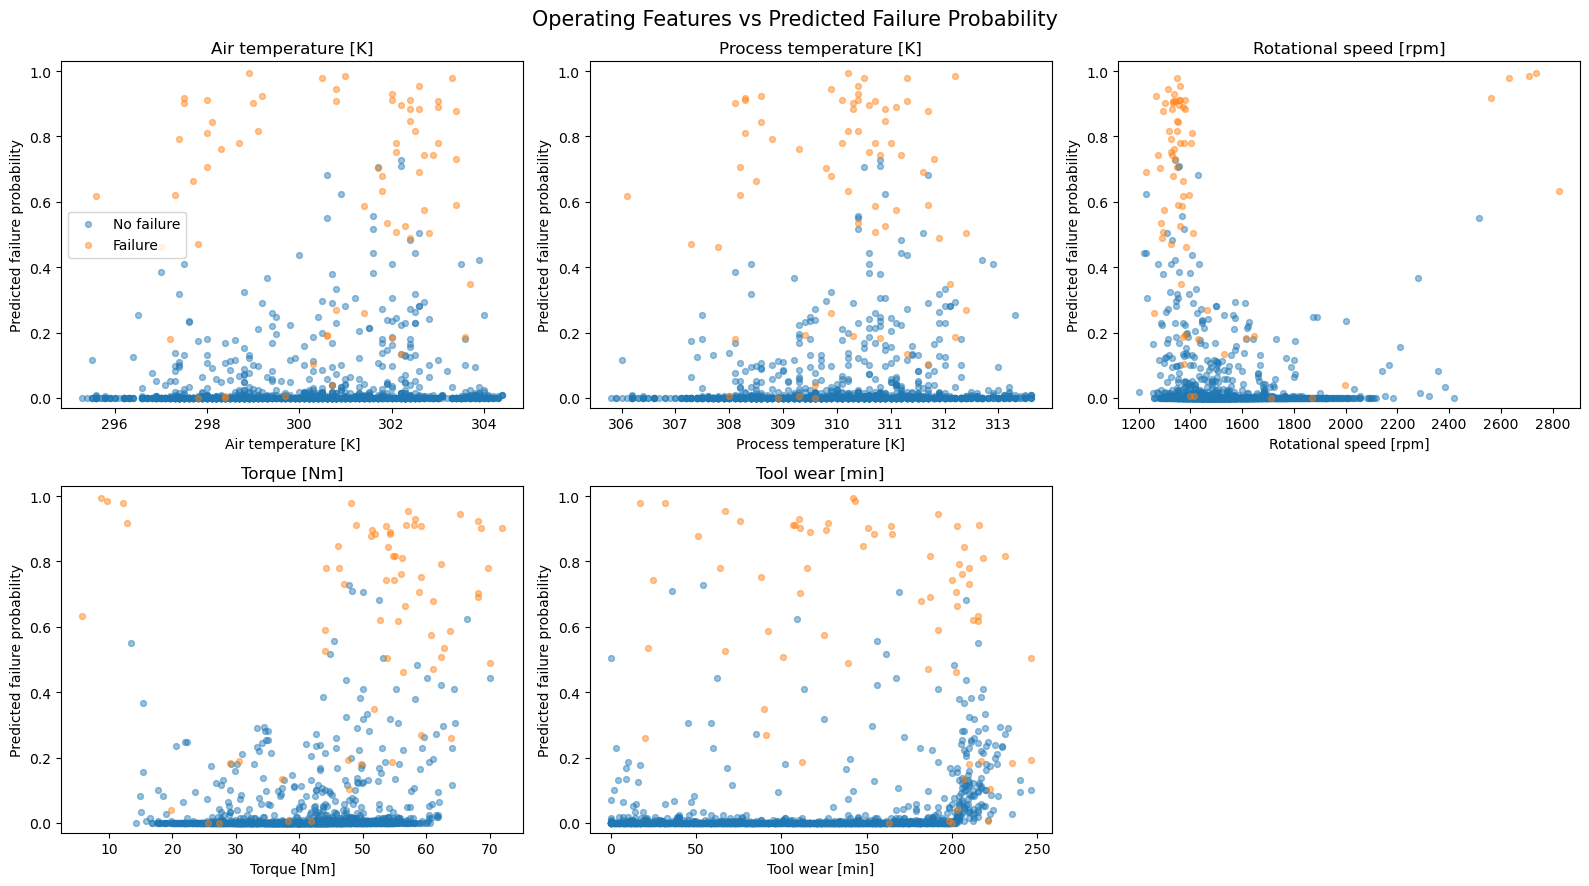

In [21]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Use the held-out test data
plot_df = X_test.copy()
plot_df["Actual Failure"] = y_test.to_numpy()
plot_df["Predicted Failure Probability"] = (
    rf_model.predict_proba(X_test)[:, 1]
)

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, feature in enumerate(numerical_features):
    ax = axes[i]

    for failure_label, label in [(0, "No failure"), (1, "Failure")]:
        subset = plot_df[plot_df["Actual Failure"] == failure_label]

        ax.scatter(
            subset[feature],
            subset["Predicted Failure Probability"],
            alpha=0.45,
            s=18,
            label=label
        )

    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("Predicted failure probability")
    ax.set_ylim(-0.03, 1.03)

axes[5].axis("off")
axes[0].legend()
plt.suptitle(
    "Operating Features vs Predicted Failure Probability",
    fontsize=15
)
plt.tight_layout()
plt.show()

## Calibration plot: are predicted probabilities trustworthy?

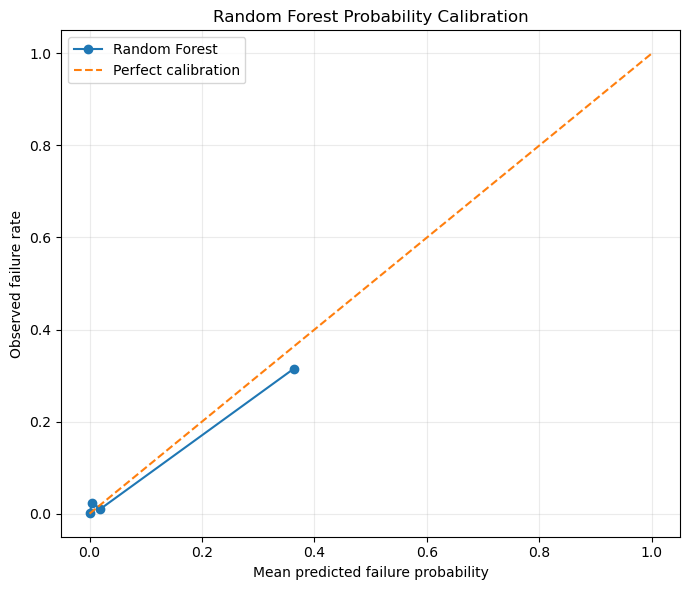

Brier score: 0.0124


In [25]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

probabilities = rf_model.predict_proba(X_test)[:, 1]

observed_rate, mean_predicted = calibration_curve(
    y_test,
    probabilities,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    mean_predicted,
    observed_rate,
    marker="o",
    label="Random Forest"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted failure probability")
plt.ylabel("Observed failure rate")
plt.title("Random Forest Probability Calibration")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(
    "Brier score:",
    round(brier_score_loss(y_test, probabilities), 4)
)

## Compare explanations across multiple machines

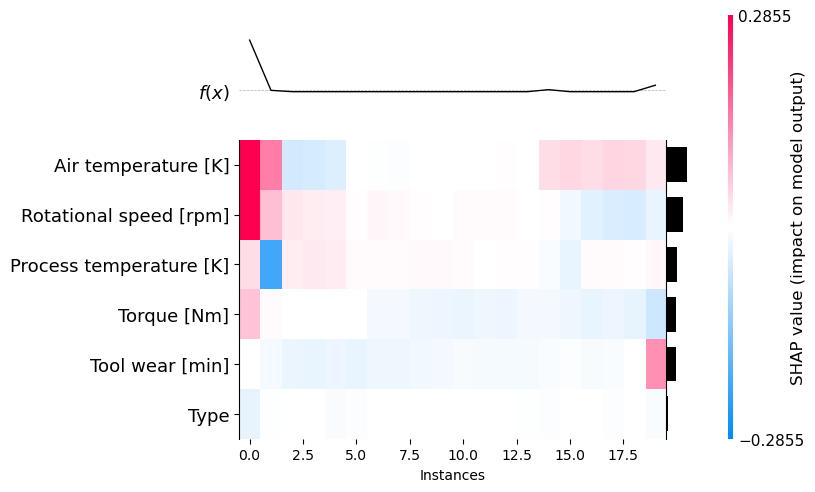

<Axes: xlabel='Instances'>

In [26]:
shap.plots.heatmap(failure_shap)

## Examine one feature's contribution

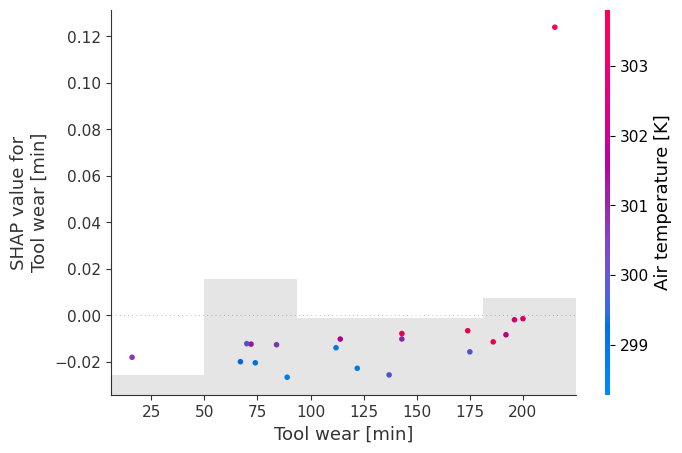

In [28]:
shap.plots.scatter(
    failure_shap[:, "Tool wear [min]"],
    color=failure_shap
)

# confuson matrix 

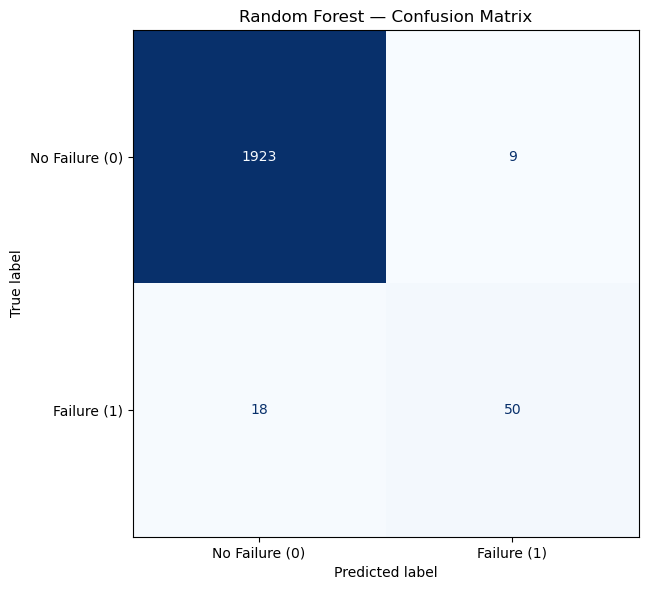

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict machine failure using the Random Forest
y_pred = rf_model.predict(X_test)

# Build the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Display it
display_labels = ["No Failure (0)", "Failure (1)"]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

## maintenance priority matrix

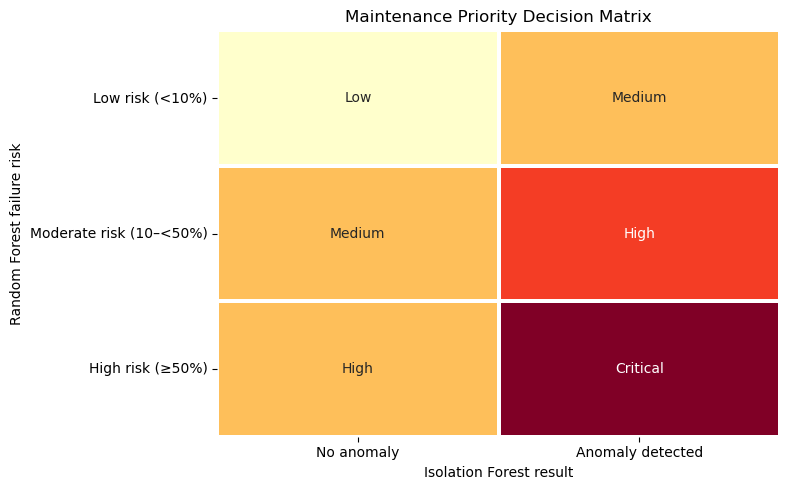

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

priority_matrix = pd.DataFrame(
    [
        ["Low", "Medium"],
        ["Medium", "High"],
        ["High", "Critical"]
    ],
    index=[
        "Low risk (<10%)",
        "Moderate risk (10–<50%)",
        "High risk (≥50%)"
    ],
    columns=["No anomaly", "Anomaly detected"]
)

fig, ax = plt.subplots(figsize=(8, 5))

sns.heatmap(
    [[1, 2], [2, 3], [2, 4]],
    annot=priority_matrix.values,
    fmt="",
    cmap="YlOrRd",
    cbar=False,
    linewidths=1.5,
    linecolor="white",
    xticklabels=priority_matrix.columns,
    yticklabels=priority_matrix.index,
    ax=ax
)

ax.set_title("Maintenance Priority Decision Matrix")
ax.set_xlabel("Isolation Forest result")
ax.set_ylabel("Random Forest failure risk")

plt.tight_layout()
plt.show()

## model performance summary

In [34]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    brier_score_loss
)

y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, list(rf_model.classes_).index(1)]

performance_summary = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "F1 Score",
        "PR AUC (Average Precision)",
        "ROC AUC",
        "Brier Score"
    ],
    "Value": [
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        average_precision_score(y_test, y_prob),
        roc_auc_score(y_test, y_prob),
        brier_score_loss(y_test, y_prob)
    ]
})

performance_summary["Value"] = performance_summary["Value"].round(4)
display(performance_summary)

,Metric,Value
0,Precision,0.8475
1,Recall,0.7353
2,F1 Score,0.7874
3,PR AUC (Average Precision),0.8362
4,ROC AUC,0.9710
5,Brier Score,0.0124
